In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("=== UNSUPERVISED LEARNING TUTORIAL ===")
print("What is Unsupervised Learning?")
print("- Learning patterns from data WITHOUT labeled outcomes")
print("- Finding hidden structures in data")
print("- Main types: Clustering and Dimensionality Reduction\n")

# Load the dataset
print("1. LOADING AND EXPLORING DATA")
print("-" * 40)

=== UNSUPERVISED LEARNING TUTORIAL ===
What is Unsupervised Learning?
- Learning patterns from data WITHOUT labeled outcomes
- Finding hidden structures in data
- Main types: Clustering and Dimensionality Reduction

1. LOADING AND EXPLORING DATA
----------------------------------------


In [3]:
 #Load data
df = pd.read_csv('/content/drive/MyDrive/diabetes.csv')
print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print("\nFirst few rows:")
df.head()


Dataset shape: (768, 9)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

First few rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
print("\nBasic statistics:")
print(df.describe())


Basic statistics:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.00000

In [5]:
# Check for missing values
print(f"\nMissing values:\n{df.isnull().sum()}")

# Separate features from outcome (we won't use outcome for unsupervised learning)
features = df.drop('Outcome', axis=1)
outcome = df['Outcome']  # Keep for validation later

print(f"\nFeature columns for unsupervised learning: {list(features.columns)}")


Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Feature columns for unsupervised learning: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [6]:
print("\n\n2. DATA PREPROCESSING")
print("-" * 40)

# Standardize the features (important for unsupervised learning)
print("Why standardize?")
print("- Different features have different scales (e.g., Age vs BMI)")
print("- Clustering algorithms are sensitive to scale")
print("- Standardization makes all features equally important\n")

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)
features_scaled_df = pd.DataFrame(features_scaled, columns=features.columns)

print("Before standardization:")
print(features.describe().round(2))
print("\nAfter standardization:")
print(features_scaled_df.describe().round(2))



2. DATA PREPROCESSING
----------------------------------------
Why standardize?
- Different features have different scales (e.g., Age vs BMI)
- Clustering algorithms are sensitive to scale
- Standardization makes all features equally important

Before standardization:
       Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin     BMI  \
count       768.00   768.00         768.00         768.00   768.00  768.00   
mean          3.85   120.89          69.11          20.54    79.80   31.99   
std           3.37    31.97          19.36          15.95   115.24    7.88   
min           0.00     0.00           0.00           0.00     0.00    0.00   
25%           1.00    99.00          62.00           0.00     0.00   27.30   
50%           3.00   117.00          72.00          23.00    30.50   32.00   
75%           6.00   140.25          80.00          32.00   127.25   36.60   
max          17.00   199.00         122.00          99.00   846.00   67.10   

       DiabetesPedigreeFun



3. CLUSTERING ANALYSIS
----------------------------------------
What is Clustering?
- Grouping similar data points together
- Points in same cluster are more similar to each other
- Points in different clusters are different from each other

Finding optimal number of clusters using Elbow Method...


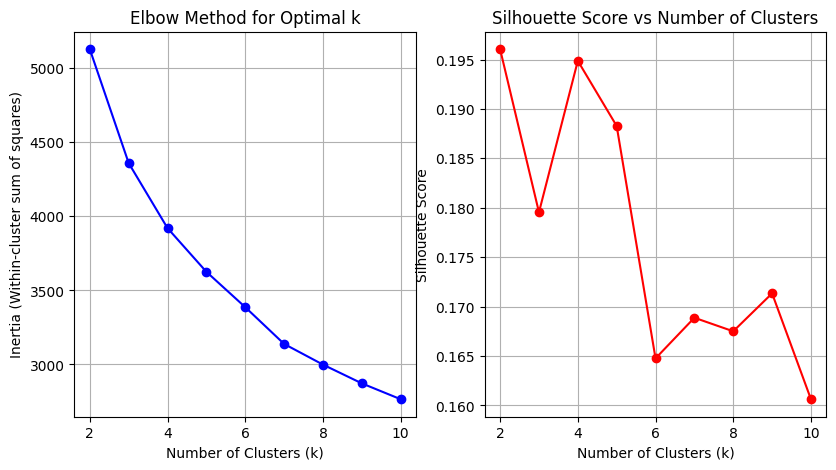

In [7]:
print("\n\n3. CLUSTERING ANALYSIS")
print("-" * 40)
print("What is Clustering?")
print("- Grouping similar data points together")
print("- Points in same cluster are more similar to each other")
print("- Points in different clusters are different from each other\n")

# Find optimal number of clusters using Elbow Method
print("Finding optimal number of clusters using Elbow Method...")
inertias = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(features_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(features_scaled, kmeans.labels_))

# Plot elbow curve
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(k_range, inertias, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-cluster sum of squares)')
plt.title('Elbow Method for Optimal k')
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(k_range, silhouette_scores, 'ro-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs Number of Clusters')
plt.grid(True)

In [8]:
# Apply K-means with optimal number of clusters (let's use k=3)
optimal_k = 3
print(f"\nApplying K-means clustering with k={optimal_k}")

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(features_scaled)

# Add cluster labels to dataframe
df_clustered = df.copy()
df_clustered['Cluster'] = cluster_labels

print(f"Silhouette Score: {silhouette_score(features_scaled, cluster_labels):.3f}")
print("(Silhouette Score range: -1 to 1, higher is better)")



Applying K-means clustering with k=3
Silhouette Score: 0.180
(Silhouette Score range: -1 to 1, higher is better)


In [9]:
# Analyze clusters
print(f"\nCluster distribution:")
cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()
for i, count in enumerate(cluster_counts):
    print(f"Cluster {i}: {count} patients ({count/len(df)*100:.1f}%)")


Cluster distribution:
Cluster 0: 216 patients (28.1%)
Cluster 1: 337 patients (43.9%)
Cluster 2: 215 patients (28.0%)


In [10]:
# ============================================================================
print("\n\n4. DIMENSIONALITY REDUCTION")
print("-" * 40)
print("What is Dimensionality Reduction?")
print("- Reducing number of features while keeping important information")
print("- Helps visualize high-dimensional data")
print("- Principal Component Analysis (PCA) is most common method\n")



4. DIMENSIONALITY REDUCTION
----------------------------------------
What is Dimensionality Reduction?
- Reducing number of features while keeping important information
- Helps visualize high-dimensional data
- Principal Component Analysis (PCA) is most common method



In [11]:
# Apply PCA
print("Applying PCA...")
pca = PCA()
features_pca = pca.fit_transform(features_scaled)

# Explained variance ratio
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("Explained variance by each component:")
for i, var in enumerate(explained_variance):
    print(f"PC{i+1}: {var:.3f} ({var*100:.1f}%)")

print(f"\nCumulative variance explained by first 2 components: {cumulative_variance[1]:.3f} ({cumulative_variance[1]*100:.1f}%)")


Applying PCA...
Explained variance by each component:
PC1: 0.262 (26.2%)
PC2: 0.216 (21.6%)
PC3: 0.129 (12.9%)
PC4: 0.109 (10.9%)
PC5: 0.095 (9.5%)
PC6: 0.085 (8.5%)
PC7: 0.052 (5.2%)
PC8: 0.051 (5.1%)

Cumulative variance explained by first 2 components: 0.478 (47.8%)


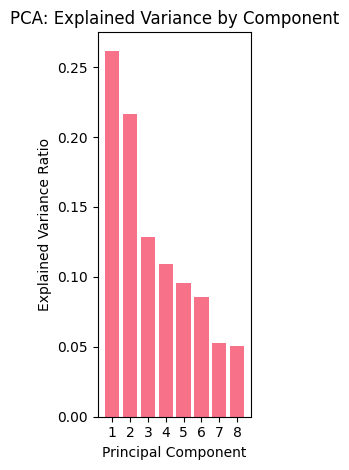

In [12]:
# Plot explained variance
plt.subplot(1, 3, 3)
plt.bar(range(1, len(explained_variance)+1), explained_variance)
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.title('PCA: Explained Variance by Component')
plt.xticks(range(1, len(explained_variance)+1))

plt.tight_layout()
plt.show()



5. VISUALIZATION
----------------------------------------


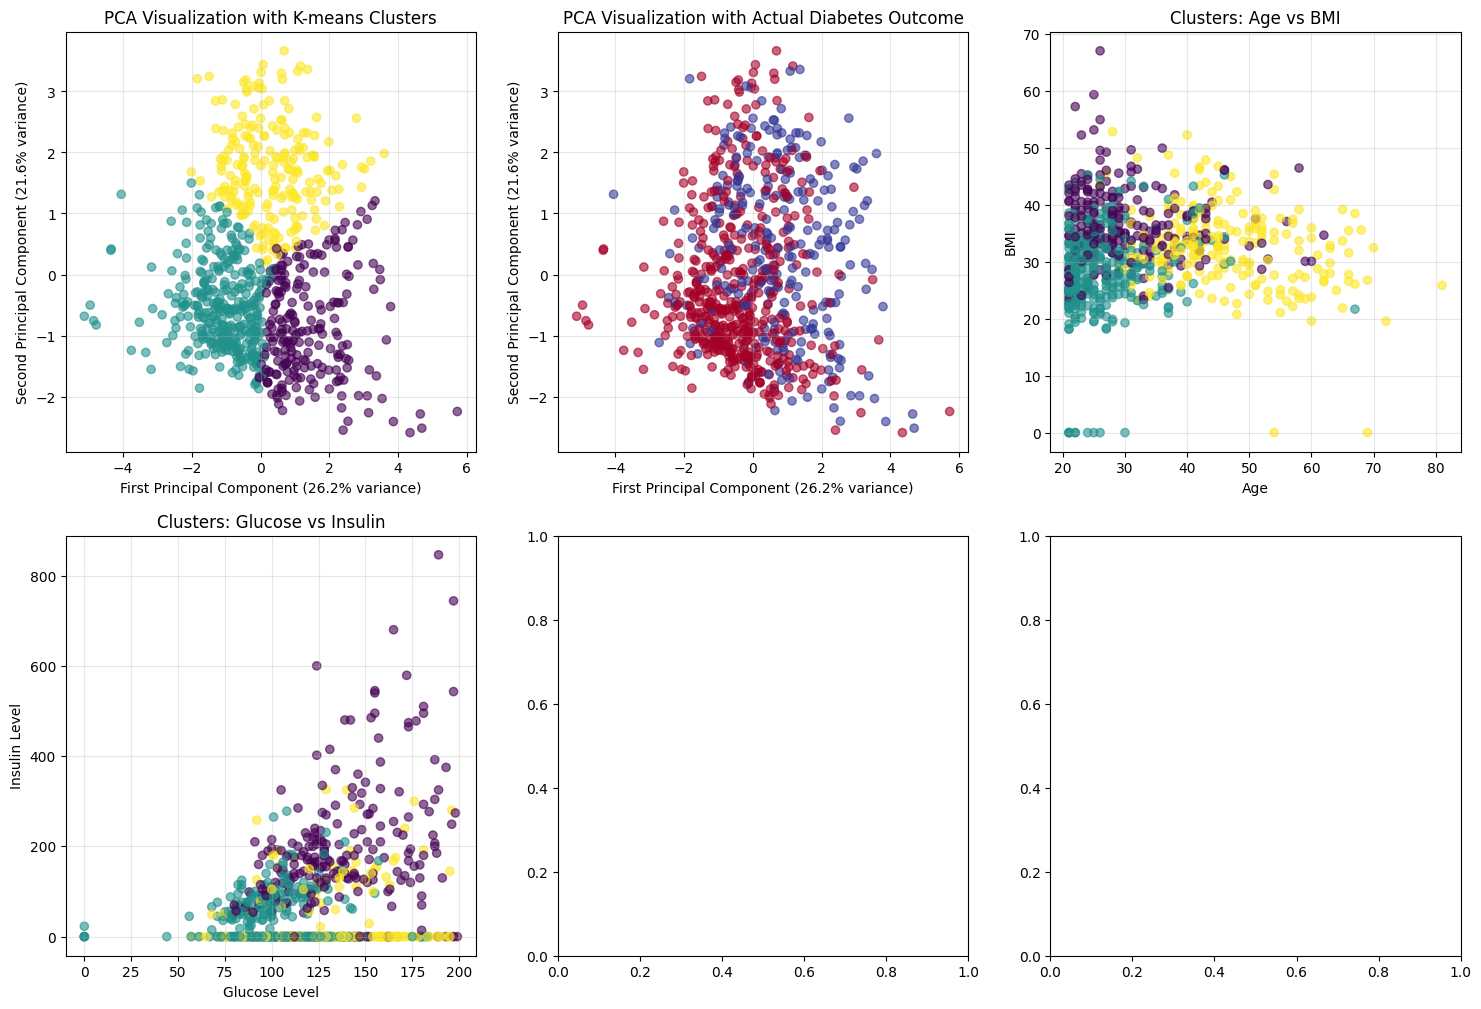

In [13]:
# ============================================================================
print("\n\n5. VISUALIZATION")
print("-" * 40)

# Create comprehensive visualization
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Plot 1: PCA visualization with clusters
axes[0, 0].scatter(features_pca[:, 0], features_pca[:, 1], c=cluster_labels, cmap='viridis', alpha=0.6)
axes[0, 0].set_xlabel(f'First Principal Component ({explained_variance[0]:.1%} variance)')
axes[0, 0].set_ylabel(f'Second Principal Component ({explained_variance[1]:.1%} variance)')
axes[0, 0].set_title('PCA Visualization with K-means Clusters')
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: PCA visualization with actual diabetes outcome
axes[0, 1].scatter(features_pca[:, 0], features_pca[:, 1], c=outcome, cmap='RdYlBu', alpha=0.6)
axes[0, 1].set_xlabel(f'First Principal Component ({explained_variance[0]:.1%} variance)')
axes[0, 1].set_ylabel(f'Second Principal Component ({explained_variance[1]:.1%} variance)')
axes[0, 1].set_title('PCA Visualization with Actual Diabetes Outcome')
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Cluster characteristics - Age vs BMI
axes[0, 2].scatter(df['Age'], df['BMI'], c=cluster_labels, cmap='viridis', alpha=0.6)
axes[0, 2].set_xlabel('Age')
axes[0, 2].set_ylabel('BMI')
axes[0, 2].set_title('Clusters: Age vs BMI')
axes[0, 2].grid(True, alpha=0.3)

# Plot 4: Cluster characteristics - Glucose vs Insulin
axes[1, 0].scatter(df['Glucose'], df['Insulin'], c=cluster_labels, cmap='viridis', alpha=0.6)
axes[1, 0].set_xlabel('Glucose Level')
axes[1, 0].set_ylabel('Insulin Level')
axes[1, 0].set_title('Clusters: Glucose vs Insulin')
axes[1, 0].grid(True, alpha=0.3)
